In [1]:
from pathlib import Path

DATA = Path("../data/extracted")

for biome in ["amazon", "atlantic"]:
    print(f"\n== {biome} ==")
    folders = sorted({p.parent for p in (DATA / biome).rglob("*") if p.is_file()})
    for d in folders:
        n_tif = len(list(d.glob("*.tif*")))
        n_png = len(list(d.glob("*.png")))
        print(d.relative_to(DATA), "->", n_tif, "tif,", n_png, "png")


== amazon ==
amazon/AMAZON/Test/image -> 20 tif, 0 png
amazon/AMAZON/Test/mask -> 20 tif, 0 png
amazon/AMAZON/Training/image -> 499 tif, 0 png
amazon/AMAZON/Training/label -> 499 tif, 0 png
amazon/AMAZON/Validation/images -> 100 tif, 0 png
amazon/AMAZON/Validation/masks -> 101 tif, 0 png

== atlantic ==
atlantic/ATLANTIC FOREST/Test/image -> 20 tif, 0 png
atlantic/ATLANTIC FOREST/Test/mask -> 20 tif, 0 png
atlantic/ATLANTIC FOREST/Training/image -> 485 tif, 0 png
atlantic/ATLANTIC FOREST/Training/label -> 485 tif, 0 png
atlantic/ATLANTIC FOREST/Validation/images -> 100 tif, 0 png
atlantic/ATLANTIC FOREST/Validation/masks -> 100 tif, 0 png


In [2]:
BASES = {
    "amazon": DATA / "amazon" / "AMAZON",
    "atlantic": DATA / "atlantic" / "ATLANTIC FOREST",
}
# (split, image folder, mask folder) for each biome
FOLDERS = {
    "amazon": [("Training", "image", "label"), ("Validation", "images", "masks"), ("Test", "image", "mask")],
    "atlantic": [("Training", "image", "label"), ("Validation", "images", "masks"), ("Test", "image", "mask")],
}

for biome, base in BASES.items():
    for split, img_dir, msk_dir in FOLDERS[biome]:
        imgs = {p.name for p in (base / split / img_dir).glob("*.tif*")}
        msks = {p.name for p in (base / split / msk_dir).glob("*.tif*")}
        print(f"{biome:9s} {split:10s} images={len(imgs):4d} masks={len(msks):4d} "
              f"| images without mask: {len(imgs - msks)} | masks without image: {sorted(msks - imgs)}")

amazon    Training   images= 499 masks= 499 | images without mask: 0 | masks without image: []
amazon    Validation images= 100 masks= 101 | images without mask: 0 | masks without image: ['S2B_MSIL2A_20200202T141649_N0213_R010_T20LQN_20200202T164215_12_07.tif.aux.xml']
amazon    Test       images=  20 masks=  20 | images without mask: 0 | masks without image: []
atlantic  Training   images= 485 masks= 485 | images without mask: 0 | masks without image: []
atlantic  Validation images= 100 masks= 100 | images without mask: 0 | masks without image: []
atlantic  Test       images=  20 masks=  20 | images without mask: 0 | masks without image: []


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [19..6232].


image: S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_01_07.tif (4, 512, 512) uint16 bands: 4
per-band min/max: [(47, 5884), (77, 6112), (19, 6232), (149, 6784)]
mask: (512, 512) uint8 unique values: [0 1]


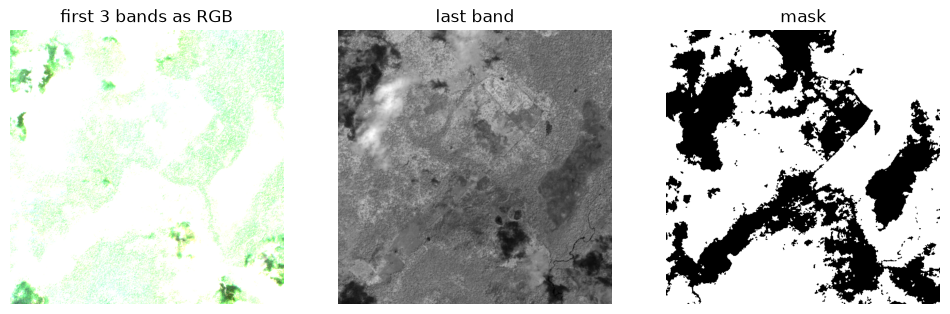

In [3]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

base = BASES["amazon"] / "Training"
img_path = sorted((base / "image").glob("*.tif*"))[0]
msk_path = base / "label" / img_path.name

with rasterio.open(img_path) as src:
    img = src.read()
    print("image:", img_path.name, img.shape, img.dtype, "bands:", src.count)
    print("per-band min/max:", [(int(b.min()), int(b.max())) for b in img])

with rasterio.open(msk_path) as src:
    msk = src.read(1)
    print("mask:", msk.shape, msk.dtype, "unique values:", np.unique(msk))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(np.transpose(img[:3], (1, 2, 0))); ax[0].set_title("first 3 bands as RGB")
ax[1].imshow(img[-1], cmap="gray"); ax[1].set_title("last band")
ax[2].imshow(msk, cmap="gray"); ax[2].set_title("mask")
for a in ax: a.axis("off")
plt.show()

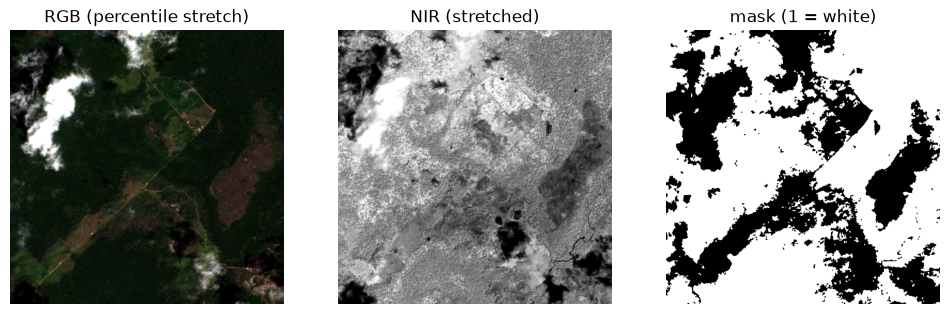

amazon: dtypes={'uint16'} | max range=4929-7660 | p99 range=3371-4340 | mask=1 fraction: 0.14-1.00
atlantic: dtypes={'uint16'} | max range=5457-12864 | p99 range=3204-6540 | mask=1 fraction: 0.09-0.75


In [4]:
import random

def stretch(a, lo=2, hi=98):
    out = np.zeros(a.shape, dtype=np.float32)
    for i in range(a.shape[0]):
        l, h = np.percentile(a[i], [lo, hi])
        out[i] = np.clip((a[i] - l) / (h - l + 1e-6), 0, 1)
    return out

# 1) properly scaled view of the same image
s = stretch(img)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(np.transpose(s[:3], (1, 2, 0))); ax[0].set_title("RGB (percentile stretch)")
ax[1].imshow(s[3], cmap="gray"); ax[1].set_title("NIR (stretched)")
ax[2].imshow(msk, cmap="gray"); ax[2].set_title("mask (1 = white)")
for a in ax: a.axis("off")
plt.show()

# 2) is the value range consistent across files?
random.seed(0)
for biome in ["amazon", "atlantic"]:
    base = BASES[biome] / "Training"
    files = random.sample(sorted((base / "image").glob("*.tif")), 30)
    dtypes, maxes, p99s, fg = set(), [], [], []
    for f in files:
        with rasterio.open(f) as src:
            a = src.read()
        with rasterio.open(base / "label" / f.name) as src:
            m = src.read(1)
        dtypes.add(str(a.dtype)); maxes.append(a.max()); p99s.append(np.percentile(a, 99)); fg.append(m.mean())
    print(f"{biome}: dtypes={dtypes} | max range={min(maxes)}-{max(maxes)} "
          f"| p99 range={int(min(p99s))}-{int(max(p99s))} | mask=1 fraction: {min(fg):.2f}-{max(fg):.2f}")

In [5]:
import json

def load_tif(path):
    with rasterio.open(path) as src:
        return src.read()

def to_reflectance(a):
    return np.clip(a.astype(np.float32) / 10000.0, 0.0, 1.0)

n_pix = 0
s = np.zeros(4, dtype=np.float64)
sq = np.zeros(4, dtype=np.float64)
fg = {"amazon": [0, 0], "atlantic": [0, 0]}   # [forest pixels, total pixels]

for biome in ["amazon", "atlantic"]:
    base = BASES[biome] / "Training"
    for f in sorted((base / "image").glob("*.tif")):
        x = to_reflectance(load_tif(f)).reshape(4, -1).astype(np.float64)
        s += x.sum(axis=1)
        sq += (x ** 2).sum(axis=1)
        n_pix += x.shape[1]
        m = load_tif(base / "label" / f.name)[0]
        fg[biome][0] += int(m.sum())
        fg[biome][1] += m.size

mean = s / n_pix
std = np.sqrt(sq / n_pix - mean ** 2)

print("band order: R, G, B, NIR")
print("mean:", np.round(mean, 4))
print("std: ", np.round(std, 4))
for b, (f_, t_) in fg.items():
    print(f"{b}: forest fraction = {f_ / t_:.3f}")

stats = {"scale": 10000.0, "mean": mean.tolist(), "std": std.tolist()}
Path("../data/band_stats.json").write_text(json.dumps(stats, indent=2))
print("saved ../data/band_stats.json")

band order: R, G, B, NIR
mean: [0.0581 0.065  0.0391 0.2981]
std:  [0.0466 0.0319 0.0281 0.0789]
amazon: forest fraction = 0.529
atlantic: forest fraction = 0.330
saved ../data/band_stats.json


In [6]:
import torch, rasterio
print(torch.__version__, rasterio.__version__)

2.15.0+cpu 1.5.2
